# Automatic ROI Extraction — preprocessing + validation pipeline

A geometry-only preprocessing pipeline plus a table-only validation suite for
cervical colposcopy images.

**Note on scope:** every QI-SABP preprocessing technique and its configuration
have been REMOVED from this notebook. That includes the quantum-inspired fused
saliency (Sobel / spectral residual / multi-scale contrast / local entropy /
whiteness), glare handling for saliency, soft and hard masks with hole
filling, rim/size rules, edge-aware continuous bit allocation, adaptive
dithered quantization, YCbCr 4:2:0 chroma subsampling, NLM pre-denoise,
bilateral post-filtering and partial histogram matching, together with all of
their configuration blocks, USE flags, ablation sweeps and provenance cells.
No QI-SABP code or config remains.

## What "Automatic ROI Extraction" does

The preprocessing is lossless and geometry-only: it selects *where* the tissue
is and discards everything else, without altering a single pixel value inside
the selected region.

1. **Field-of-view (FOV) detection.** Pixels brighter than `ROI_FOV_THR` are
   candidate tissue; a morphological open removes speckle; the largest
   connected component is kept and its holes are filled; a convex hull
   (intersected with the component's bounding box) fills the black triangles
   and zigzag frame teeth seen on real colposcopy frames; an elliptical close
   smooths the boundary.
2. **Rim safety margin.** The FOV is eroded by `ROI_MARGIN_ERODE` px
   (`border_value=1`, so the margin applies at the circular rim, not at the
   rectangular frame edge) so the vignette and speculum shadow at the boundary
   are excluded.
3. **Component cleanup.** Only the largest component is kept, holes are
   refilled and small gaps are closed.
4. **Failure guards.** If the cleaned ROI covers less than `ROI_MIN_AREA_FRAC`
   of the frame, the notebook falls back to the un-eroded FOV and, if needed,
   to the full frame, so an empty extraction can never occur silently.
5. **Extraction.** Pixels OUTSIDE the ROI are set to 0 (black); pixels INSIDE
   the ROI are copied unchanged.

## Output

* uint8 RGB image, same shape as the input, with the original pixel values
  inside the ROI and zeros outside.
* The boolean ROI mask, the tight bounding box and coverage statistics
  (ROI and FOV as a fraction of the frame) for downstream use.

It is NOT a compression scheme and NOT an enhancement method: inside the ROI
the image is bit-identical to the input.

## What this notebook does NOT claim

* It does NOT enhance, denoise, sharpen or recolour anything (by design).
* It does NOT compare preprocessing techniques against each other.
* It does NOT demonstrate a clinical benefit on this single patient.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, glob, time, math, random, warnings, platform
import hashlib as _hashlib

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV artefacts.
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nAutomatic ROI Extraction + Validation — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



Automatic ROI Extraction + Validation — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 — Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   NOTE: every QI-SABP configuration block (saliency fusion weights,
#   glare/rim/soft-mask/hard-mask handling, bit allocation, dithering,
#   YCbCr 4:2:0, NLM, bilateral, histogram matching and all USE_*
#   flags) has been REMOVED. The only preprocessing in this notebook
#   is Automatic ROI Extraction.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Automatic ROI extraction (the only preprocessing) ----
# 1) FOV detection: pixels brighter than ROI_FOV_THR are candidate tissue.
ROI_FOV_THR      = 15      # luminance threshold for tissue candidacy
ROI_OPEN_KSIZE   = 5       # elliptical open kernel (removes speckle)
ROI_CLOSE_KSIZE  = 11      # elliptical close kernel after the convex hull
                           # (smooths the zigzag frame teeth)
# 2) Rim safety margin: erode the FOV by this many px (border_value=1, so the
#    margin applies at the circular rim, not at the rectangular frame edge).
ROI_MARGIN_ERODE = 4       # px; 0 disables the margin
# 3) Cleanup: after the margin, keep the largest component, refill holes and
#    close small gaps with this elliptical kernel.
ROI_SMOOTH_KSIZE = 5
# 4) Guards: if the final ROI covers less than ROI_MIN_AREA_FRAC of the frame,
#    fall back to the un-eroded FOV; if even that is too small, keep the full
#    frame (with a warning) so an empty extraction can never occur silently.
ROI_MIN_AREA_FRAC = 0.05

# ---- Validation (Part B) ----
VESSEL_TOP_PCT   = 10      # Vessel Dice: Dice of the top-X% Frangi vessel pixels
N_BOOTSTRAP      = 2000    # cluster bootstrap resamples for the 95% CI

# ---- Validation batch ----
SUBSET_PER_CLASS = None    # None = use every image found

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  ROI extraction: thr={ROI_FOV_THR}, open={ROI_OPEN_KSIZE}, "
      f"hull-close={ROI_CLOSE_KSIZE}, margin_erode={ROI_MARGIN_ERODE} px, "
      f"smooth={ROI_SMOOTH_KSIZE}, min_area_frac={ROI_MIN_AREA_FRAC}")
print(f"  Validation: vessel top {VESSEL_TOP_PCT}% | bootstrap {N_BOOTSTRAP} resamples")
print("  QI-SABP preprocessing: REMOVED (no QI-SABP technique or config remains)")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  ROI extraction: thr=15, open=5, hull-close=11, margin_erode=4 px, smooth=5, min_area_frac=0.05
  Validation: vessel top 10% | bootstrap 2000 resamples
  QI-SABP preprocessing: REMOVED (no QI-SABP technique or config remains)


In [3]:
# ============================================================
# Cell 1.3 -- preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
#            NOTE: unsharp-mask sharpening was removed together with
#            the QI-SABP pipeline; loading is resize-only.
# ============================================================

def preprocess_image(img_bgr, size=IMG_SIZE):
    """BGR -> RGB -> resize. Single source of truth (resize-only)."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize.
    Case-insensitive dedupe by filename so the same physical file is never
    loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the mask-based evaluation
    has a real target when the real dataset is not attached.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


In [4]:
# ============================================================
# Cell 1.4 -- Automatic ROI Extraction
#   Lossless, geometry-only extraction of the tissue region.
#   (compute_fov_mask is promoted from the old Step-4 FOV helper;
#    all QI-SABP saliency/mask/quantization functions are removed.)
# ============================================================

def compute_fov_mask(img_rgb, thr=None, open_ksize=None, close_ksize=None):
    """Field-of-view (tissue) mask.

    Bright-pixel threshold -> morphological open -> largest connected
    component -> hole fill -> convex-hull notch fill (intersected with the
    component's bounding box so the hull cannot extend past the bright
    region) -> elliptical close. The convex-hull step fills the black
    triangles / zigzag frame teeth seen on real colposcopy frames.

    Returns a boolean mask (H, W).
    """
    thr = ROI_FOV_THR if thr is None else thr
    open_ksize = ROI_OPEN_KSIZE if open_ksize is None else open_ksize
    close_ksize = ROI_CLOSE_KSIZE if close_ksize is None else close_ksize
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    if open_ksize > 1:
        k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                                           (open_ksize, open_ksize))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k_open)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k_big = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k_big)
    ys, xs = np.where(fov)
    if len(ys) < 3:
        return fov
    # Convex hull of the FOV mask, intersected with the component's
    # bounding box: fills notches at the frame edges without extending
    # past the bright region in any direction.
    pts = np.stack([xs, ys], axis=1).astype(np.int32)
    hull = cv2.convexHull(pts)
    hull_mask = np.zeros(g.shape, dtype=np.uint8)
    cv2.fillConvexPoly(hull_mask, hull, 1)
    hull_mask = hull_mask.astype(bool)
    x0, x1 = int(xs.min()), int(xs.max())
    y0, y1 = int(ys.min()), int(ys.max())
    bbox = np.zeros(g.shape, dtype=bool)
    bbox[y0:y1+1, x0:x1+1] = True
    hull_mask = hull_mask & bbox
    if close_ksize > 1:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                                           (close_ksize, close_ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                     cv2.MORPH_CLOSE, kernel).astype(bool)
    return fov | hull_mask


def extract_roi(img_rgb, return_artefacts=False, params=None):
    """Automatic ROI Extraction.

    Steps:
      1. FOV detection (compute_fov_mask).
      2. Rim safety margin: erode by ROI_MARGIN_ERODE px (border_value=1,
         so the margin applies at the circular rim, not at the frame edge).
      3. Cleanup: largest component only, holes refilled, small gaps closed.
      4. Guards: fall back to the FOV / full frame if the ROI gets too small.
      5. Extraction: pixels OUTSIDE the ROI are set to 0 (black); pixels
         INSIDE the ROI are copied unchanged (lossless).

    Returns:
        proc : uint8 RGB, same shape as the input
        roi  : bool mask (H, W), True inside the extracted ROI
        info : dict with fov_area_frac, roi_area_frac, bbox (x0, y0, w, h)
    (only `proc` when return_artefacts=False)
    """
    p = dict(params or {})
    thr = p.get("thr", ROI_FOV_THR)
    margin = int(p.get("margin", ROI_MARGIN_ERODE))
    min_frac = float(p.get("min_area_frac", ROI_MIN_AREA_FRAC))

    img = np.asarray(img_rgb)
    H, W = img.shape[:2]

    # 1) FOV detection
    fov = compute_fov_mask(img, thr=thr)
    fov_frac = float(fov.mean())

    # 2) rim safety margin
    roi = (ndimage.binary_erosion(fov, iterations=margin, border_value=1)
           if margin > 0 else fov.copy())

    # 3) cleanup: largest component, refill holes, close small gaps
    n, lab, st, _ = cv2.connectedComponentsWithStats(roi.astype(np.uint8))
    if n > 1:
        k_big = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
        roi = (lab == k_big)
    roi = ndimage.binary_fill_holes(roi)
    if ROI_SMOOTH_KSIZE > 1:
        k_smooth = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (ROI_SMOOTH_KSIZE, ROI_SMOOTH_KSIZE))
        roi = cv2.morphologyEx(roi.astype(np.uint8),
                               cv2.MORPH_CLOSE, k_smooth).astype(bool)

    # 4) guards
    fallback = ""
    if float(roi.mean()) < min_frac:
        roi = fov.copy()
        fallback = "fov"
    if float(roi.mean()) < min_frac:
        roi = np.ones((H, W), dtype=bool)
        fallback = "full_frame"
    if fallback:
        print(f"[roi] small-region guard triggered -> fallback: {fallback} "
              f"(min_area_frac={min_frac})")

    # 5) lossless extraction: black out everything outside the ROI
    proc = img.copy()
    proc[~roi] = 0

    ys, xs = np.where(roi)
    if len(ys) > 0:
        bbox = (int(xs.min()), int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    else:
        bbox = (0, 0, W, H)

    info = {"fov_area_frac": fov_frac,
            "roi_area_frac": float(roi.mean()),
            "bbox": bbox}
    if return_artefacts:
        return proc.astype(np.uint8), roi, info
    return proc.astype(np.uint8)


def roi_extract(img, params=None, seed=0):
    """Automatic ROI Extraction, exposed to the Part B validator.

    Signature: roi_extract(img_uint8_RGB, params_dict, seed) -> uint8 RGB.
    `params` and `seed` are accepted for API compatibility with the old
    technique wrapper; the extraction is fully deterministic (geometry
    only, no randomness, no pixel-value modification inside the ROI).
    """
    return extract_roi(img, return_artefacts=False, params=params)


# ---- Smoke test on the first image ----
_sm, _sm_roi, _sm_info = extract_roi(X_raw[0], return_artefacts=True)
assert _sm.shape == X_raw[0].shape and _sm.dtype == np.uint8, \
    f"roi_extract output mismatch: {_sm.shape} {_sm.dtype}"
assert _sm_roi.shape == X_raw[0].shape[:2] and _sm_roi.dtype == bool
assert np.array_equal(roi_extract(X_raw[0]), _sm), \
    "roi_extract is not deterministic"
_mse_inside = float(((_sm.astype(np.float64) - X_raw[0].astype(np.float64)) ** 2)[_sm_roi].mean())
assert _mse_inside == 0.0, "ROI extraction must be lossless inside the ROI"
print(f"roi_extract ready | smoke test on image 0: "
      f"fov={_sm_info['fov_area_frac']:.3f}, roi={_sm_info['roi_area_frac']:.3f} of frame, "
      f"bbox={_sm_info['bbox']}, MSE inside ROI = {_mse_inside:.1f} (lossless)")


roi_extract ready | smoke test on image 0: fov=0.930, roi=0.910 of frame, bbox=(0, 13, 200, 187), MSE inside ROI = 0.0 (lossless)


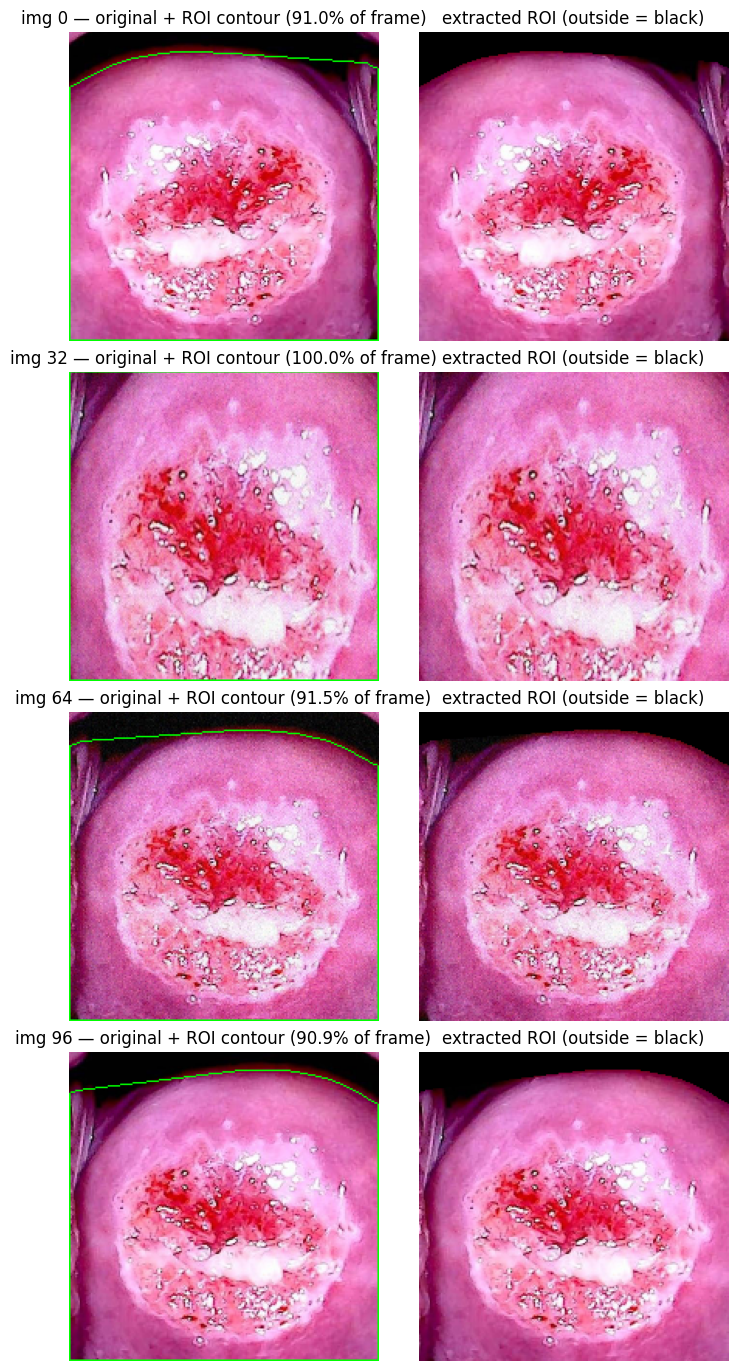

In [5]:
# ============================================================
# Cell 1.5 -- Visualise Automatic ROI Extraction on sample images
# ============================================================

def show_roi_extraction(X_arr, n_samples=4):
    """Show original + ROI contour (left) and the extracted output (right)
    for a few sample images."""
    n = min(n_samples, len(X_arr))
    step = max(1, len(X_arr) // n)
    idxs = list(range(0, len(X_arr), step))[:n]
    fig, axes = plt.subplots(len(idxs), 2, figsize=(7, 3.4 * len(idxs)),
                             constrained_layout=True)
    axes = np.atleast_2d(axes)
    for row, i in enumerate(idxs):
        img = X_arr[i]
        proc, roi, info = extract_roi(img, return_artefacts=True)
        ov = img.copy()
        cnts, _ = cv2.findContours(roi.astype(np.uint8),
                                   cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(ov, cnts, -1, (0, 255, 0), 1)
        axes[row, 0].imshow(ov)
        axes[row, 0].set_title(f"img {i} — original + ROI contour "
                               f"({info['roi_area_frac']*100:.1f}% of frame)")
        axes[row, 1].imshow(proc)
        axes[row, 1].set_title("extracted ROI (outside = black)")
        for ax in axes[row]:
            ax.axis("off")
    plt.show()

show_roi_extraction(X_raw, n_samples=4)


# Bridge — hand off Automatic ROI Extraction to Part B

Part B expects these variables:

| Part-B name | Meaning | Source in this notebook |
|-------------|---------|-------------------------|
| `X_base` | (N,200,200,3) uint8 RGB, **resize-only** | loader's `X_raw` |
| `image_ids` | unique id per image | sequential `img_NNNN` |
| `masks` | clinician lesion masks (OPTIONAL) | `masks_raw` from the loader |
| `roi_extract(img, params, seed)` | the preprocessing technique | Cell 1.4 |

Note: the old bridge reloaded a second, unsharpened image stack because the
QI-SABP pipeline sharpened its input (Step 1). Sharpening was removed together
with QI-SABP, so a single resize-only stack is handed to Part B.


In [6]:
# ============================================================
# Bridge -- hand off Automatic ROI Extraction to Part B.
# ============================================================

# --- Resize-only stack becomes the validator's X_base ---
X_base = X_raw.copy()          # 200x200, uint8 RGB (no sharpen: removed with QI-SABP)
masks = masks_raw.copy()       # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))], dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Final shape assertions ---
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert len(image_ids) == len(X_base), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)}"
assert masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

# --- Determinism smoke test (same pattern as the old technique wrapper) ---
_sm1 = roi_extract(X_base[0], {}, seed=12345)
_sm2 = roi_extract(X_base[0], {}, seed=999)
assert _sm1.shape == X_base[0].shape and _sm1.dtype == np.uint8, \
    f"roi_extract smoke test failed: got {_sm1.shape} {_sm1.dtype}"
assert np.array_equal(_sm1, _sm2), \
    "roi_extract is not deterministic across seeds"
print(f"Bridge ready | X_base (resize-only) = {X_base.shape} {X_base.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")


Bridge ready | X_base (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False


# Part B — table-only validation with 11 metrics

Single-patient, dHash-clustered frames. The frames are NOT independent.
Descriptive only — no p-values, no robustness or population claims.

**Technique:** Automatic ROI Extraction (Cell 1.4).

**Metrics (11, in 5 groups).** All computed per image, against the ORIGINAL
image, inside the technique's evaluation region only:

* Fidelity — **PSNR (dB)**, **SSIM**
* Colour — **ΔE76** (CIE76), **a\* correlation**, **|a\*| shift**
* Structure — **Vessel Dice**, **Edge IoU**
* Quality — **Sharpness ratio**, **Noise ratio**, **Saturation ratio**
* Depth — **Luma bits** (effective luma bit depth inside the region: log2 of
  the number of unique luma levels, capped at 8; replaces the QI-SABP
  analytic bit budget, which was removed)

Region note: ROI-Extraction is evaluated inside its ROI mask; the Identity
reference row is evaluated inside the full FOV (no extraction).

**Tables only.** T1 (main), T2 (ROI summary), T6 (caveats). The old
QI-SABP ablation/statistics tables (T4/T5/T7/T8) were removed together with
the technique.


In [7]:
# ============================================================
# Step 4.1 -- Freeze inputs: ROI + FOV masks, dHash cluster ids,
#             provenance hash (printed, NOT asserted).
# ============================================================

def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()


images = X_base          # (N, 200, 200, 3) uint8 RGB, resize-only
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)

# Full FOV (no margin erosion) -- evaluation region of the Identity row.
fov = np.stack([compute_fov_mask(images[i]) for i in range(n_images)])

# ROI masks -- evaluation region of ROI-Extraction (identical masks are
# regenerated by roi_extract in Step 4.3; the extraction is deterministic).
roi_masks, roi_infos = [], []
for i in range(n_images):
    _p, _r, _info = extract_roi(images[i], return_artefacts=True)
    roi_masks.append(_r)
    roi_infos.append(_info)
roi_masks = np.stack(roi_masks)

# dHash clustering (identical to the previous validator): frames within
# 4 bits of Hamming distance share a cluster.
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY))
      for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))

# Provenance hash of the frozen inputs. The old cache_hash ASSERT
# ("12f68b681210") belonged to the frozen QI-SABP Part A and was removed:
# changing the ROI configuration no longer breaks any cross-notebook contract.
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
print(f"provenance_hash = {_h.hexdigest()[:12]}  (informational only)")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters}")
print(f"  mean FOV = {fov.mean():.3f} | mean ROI = {roi_masks.mean():.3f} of frame")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


provenance_hash = 4c30f945635c  (informational only)
  n_images = 128 | n_clusters (dHash) = 7
  mean FOV = 0.958 | mean ROI = 0.947 of frame
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [8]:
# ============================================================
# Step 4.2 -- roi_validator + helper functions.
#             Computes 11 metrics inside the evaluation region only.
#             (m1..m10 reuse the previous validator implementations
#              verbatim; m11 Luma bits replaces the QI-SABP analytic
#              bit budget; m12 Time was dropped per spec.)
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)


def _vessel_dice(original, processed, mask, top_pct=None):
    """Dice of the top `top_pct` Frangi vessel pixels inside the mask.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the region, then computes 2*|A and B| / (|A| + |B|)."""
    top_pct = VESSEL_TOP_PCT if top_pct is None else top_pct
    f = np.asarray(mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum()) + float(b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom


def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)


def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])


def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)


def _specular_mask(img_rgb):
    """Specular/glare pixel mask (V >= 250 and S <= 25 in HSV)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)


def _luma_bits(img_rgb, mask):
    """m11 Luma bits: effective luma bit depth inside the mask, defined as
    log2(number of unique luma levels), capped at 8 bits. Replaces the
    QI-SABP analytic bit budget (removed with the technique)."""
    y = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    vals = y[np.asarray(mask, dtype=bool)]
    if vals.size == 0:
        return float('nan')
    return float(min(8.0, math.log2(int(np.unique(vals).size))))


def roi_validator(original, processed, eval_mask):
    """Compute 11 metrics inside eval_mask only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                        up
      m2  SSIM                             up
      m3  CIE76 dE (Delta E76)             down
      m4  a* correlation                   up
      m5  |mean a* shift|                  down
      m6  Vessel Dice (top 10% Frangi)     up
      m7  Edge IoU (Canny)                 up
      m8  Sharpness ratio (out/in)         neutral
      m9  Noise ratio (out/in)             down
      m10 Saturation ratio (out/in)        neutral
      m11 Luma bits (effective)            up
    """
    metric_keys = [f"m{i}" for i in range(1, 12)]
    f = np.asarray(eval_mask, dtype=bool)
    if not f.any():
        return {k: float('nan') for k in metric_keys}
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (region-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                        full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE (stating which: CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top VESSEL_TOP_PCT% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=VESSEL_TOP_PCT)
    # m7: Edge IoU
    m7 = _edge_iou(_edge_map(original), _edge_map(processed), f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of the high-pass residual
    #     in the smoothest 30% of the region
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). A ratio > 1
    #      means the technique adds saturated pixels; <= 1 is good.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: Luma bits (effective, inside the evaluation region)
    m11 = _luma_bits(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)


# Metric metadata (key, name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",       "fidelity",  "up"),
    ("m2",  "SSIM",            "fidelity",  "up"),
    ("m3",  "DeltaE76",        "colour",    "down"),
    ("m4",  "a* corr",         "colour",    "up"),
    ("m5",  "|a* shift|",      "colour",    "down"),
    ("m6",  "Vessel Dice",     "structure", "up"),
    ("m7",  "Edge IoU",        "structure", "up"),
    ("m8",  "Sharpness ratio", "quality",   "neutral"),
    ("m9",  "Noise ratio",     "quality",   "down"),
    ("m10", "Saturation ratio", "quality",  "neutral"),
    ("m11", "Luma bits",       "depth",     "up"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("roi_validator ready: 11 metrics (m1..m11).")


roi_validator ready: 11 metrics (m1..m11).


In [9]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for ROI-Extraction. Write per-image
#             CSV. Also cache processed images (no re-runs).
# ============================================================

# Clear stale per-technique CSVs from earlier runs (fixed location).
for _old in glob.glob(os.path.join(SAVE_DIR, "results_*.csv")):
    os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "ROI-Extraction"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB

rows = []
for i in range(n_images):
    orig = images[i]
    t0 = time.perf_counter()
    proc = roi_extract(orig, {}, seed=SEED + i)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    m = roi_validator(orig, proc, roi_masks[i])
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    m["roi_area_frac"] = roi_infos[i]["roi_area_frac"]
    m["fov_area_frac"] = roi_infos[i]["fov_area_frac"]
    _bx, _by, _bw, _bh = roi_infos[i]["bbox"]
    m["roi_bbox_w"] = _bw
    m["roi_bbox_h"] = _bh
    m["elapsed_ms"] = elapsed_ms      # diagnostics only (NOT one of the 11 metrics)
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_roi_tech = pd.DataFrame(rows)
_csv_path = os.path.join(SAVE_DIR, f"results_{TECHNIQUE}.csv")
df_roi_tech.to_csv(_csv_path, index=False)
print(f"Wrote {_csv_path} ({len(df_roi_tech)} rows)")
print(f"  Mean ROI coverage = {df_roi_tech['roi_area_frac'].mean()*100:.1f}% of frame | "
      f"mean FOV = {df_roi_tech['fov_area_frac'].mean()*100:.1f}% of frame")
print(f"  Mean elapsed = {df_roi_tech['elapsed_ms'].mean():.1f} ms/image (diagnostic only)")


  Deleted stale results\results_SRR.csv
  Deleted stale results\results_SRR_paired.csv
  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results\results_ROI-Extraction.csv (128 rows)
  Mean ROI coverage = 94.7% of frame | mean FOV = 95.8% of frame
  Mean elapsed = 10.0 ms/image (diagnostic only)


In [10]:
# ============================================================
# Step 4.4 -- Identity reference row (no extraction; full-FOV region).
# ============================================================

for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()

rows_id = []
for i in range(n_images):
    m = roi_validator(images[i], images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    m["roi_area_frac"] = float(fov[i].mean())   # its evaluation region IS the full FOV
    m["fov_area_frac"] = float(fov[i].mean())
    m["roi_bbox_w"] = images.shape[2]
    m["roi_bbox_h"] = images.shape[1]
    rows_id.append(m)

df_id = pd.DataFrame(rows_id)
_csv_path = os.path.join(SAVE_DIR, "results_Identity.csv")
df_id.to_csv(_csv_path, index=False)
print(f"Wrote {_csv_path} ({len(df_id)} rows)")
print("Identity is a REFERENCE row: lossless by construction (ideal values, not ranked).")


Wrote results\results_Identity.csv (128 rows)
Identity is a REFERENCE row: lossless by construction (ideal values, not ranked).


In [11]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate technique CSVs (fixed list).
#              Assert each technique has n_images rows and the same
#              cluster ids. Assert no NaNs in the 11 metric columns.
# ============================================================

_csv_names = [
    "results_ROI-Extraction.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(os.path.join(SAVE_DIR, f))
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {_df['technique'].iloc[0]}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any of the 11 metric columns.
_nan_cols = {}
for col in METRIC_KEYS:
    n_nan = int(merged[col].isna().sum())
    if n_nan > 0:
        _nan_cols[col] = n_nan
assert len(_nan_cols) == 0, f"NaN values found in metric columns: {_nan_cols}"
print("No NaN values in any of the 11 metric columns.")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Reading 2 CSV files (fixed list, not glob)
  results_ROI-Extraction.csv: 128 rows, technique = ROI-Extraction
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any of the 11 metric columns.
Techniques: ['Identity', 'ROI-Extraction']


In [12]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap
#              (N_BOOTSTRAP resamples, fixed seed).
#              Label: "within-patient, cluster bootstrap, not a
#              population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())


def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=N_BOOTSTRAP, seed=SEED):
    """Bootstrap CI over clusters. Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))


# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print("  WITHIN-PATIENT, cluster bootstrap, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, cluster bootstrap, NOT a population CI.


In [13]:
# ============================================================
# Step 4.7 -- Tables: T1 MAIN, T2 ROI summary, T6 caveats.
#             (T4/T5/T7/T8 were QI-SABP ablation/statistics tables
#              and were removed together with the technique.)
# ============================================================

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 MAIN ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, NOT a population CI)")
print("  The frames are NOT independent (dHash clusters from one patient).")
print("  Regions differ by construction: ROI-Extraction inside its ROI; Identity inside the full FOV.")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 110)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T2 ROI SUMMARY ----
print()
print("=" * 110)
print("T2 ROI SUMMARY  (descriptive geometry of the automatic extraction; not ranked)")
print("=" * 110)
tech_df = merged[merged["technique"] == TECHNIQUE]
print(f"  Mean ROI coverage (frame) : {tech_df['roi_area_frac'].mean()*100:6.1f}%  "
      f"(median {tech_df['roi_area_frac'].median()*100:.1f}%, "
      f"min {tech_df['roi_area_frac'].min()*100:.1f}%, "
      f"max {tech_df['roi_area_frac'].max()*100:.1f}%)")
print(f"  Mean FOV coverage (frame) : {tech_df['fov_area_frac'].mean()*100:6.1f}%")
print(f"  Mean ROI bbox (w x h)     : {tech_df['roi_bbox_w'].mean():.0f} x "
      f"{tech_df['roi_bbox_h'].mean():.0f} px")
_ret = [float((roi_masks[i] & fov[i]).sum()) / max(float(fov[i].sum()), 1.0)
        for i in range(n_images)]
print(f"  Tissue retention (ROI inside FOV / FOV): {np.mean(_ret)*100:.1f}% "
      f"(min {np.min(_ret)*100:.1f}%)")
t2_rows = []
for uc in np.unique(cluster_ids):
    idxs = np.where(cluster_ids == uc)[0]
    t2_rows.append({
        "cluster": int(uc),
        "n_images": len(idxs),
        "roi_area_frac": float(np.mean([roi_infos[i]["roi_area_frac"] for i in idxs])),
        "fov_area_frac": float(np.mean([roi_infos[i]["fov_area_frac"] for i in idxs])),
    })
t2_df = pd.DataFrame(t2_rows)
print(t2_df.round(4).to_string(index=False))

# ---- T6 CAVEATS ----
print()
print("=" * 110)
print("T6 CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    "Single patient; dHash clusters; frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "QI-SABP preprocessing (fused saliency, soft/hard masks, bit allocation, dithered "
    "quantization, YCbCr 4:2:0, NLM, bilateral, histogram matching) was REMOVED; this "
    "notebook validates Automatic ROI Extraction only.",
    "ROI extraction is LOSSLESS inside the ROI by construction: PSNR/SSIM/DeltaE76/"
    "a* correlation/Vessel Dice/Edge IoU/Sharpness-Noise-Saturation ratios are expected "
    "at their ideal values; they certify that no content was lost, they do not measure "
    "enhancement.",
    "Regions differ by construction: ROI-Extraction is scored inside its ROI (rim margin "
    "eroded); Identity is scored inside the full FOV.",
    "Identity PSNR shows the clamp value (~148 dB) because MSE = 0 is clamped at 1e-10; "
    "read it as 'identical', not as a number.",
    "Luma bits (m11) is REDEFINED for the extraction setting: effective luma bit depth = "
    "log2(unique luma levels inside the region), capped at 8. It replaces the QI-SABP "
    "analytic bit budget.",
    "No lesion masks matched on the real dataset (0/128 in the last run); lesion-level "
    "metrics are not evaluated.",
    "CIE76 dE (not CIEDE2000).",
    "Sharpness ratio (m8) and Saturation ratio (m10) are neutral diagnostics, not ranked.",
    "Vessel Dice (m6): Dice of the top 10% Frangi pixels, 2*|A and B|/(|A|+|B|).",
    "Edge IoU (m7): Canny edges; on a lossless extraction it is 1.0 by construction.",
    "elapsed_ms is stored per image for diagnostics only; it is NOT one of the 11 "
    "metrics and is not ranked.",
]
for c in caveats:
    print(f"  - {c}")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, NOT a population CI)
  The frames are NOT independent (dHash clusters from one patient).
  Regions differ by construction: ROI-Extraction inside its ROI; Identity inside the full FOV.
  Identity is a reference row (ideal values, not ranked).
                             PSNR (dB) (^)              SSIM (^)          DeltaE76 (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (^)
technique                                                                                                                                                                                                                                                             
Identity        148.131 [148.131, 148.131]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]